# 5. Planar flight with second-order-cone limits

**Goal:** move in a plane to $(p_x,p_y)=(2,1)$ and stop.
Let $x=(p_x,p_y,v_x,v_y)$ and $u=(a_x,a_y)$; minimize quadratic state tracking
and control effort with a terminal target $x_N=(2,1,0,0)$.

The dynamics are the two-dimensional double integrator. Constraints are
$$\|u_k\|_2\le1.2,\qquad\|(v_{x,k},v_{y,k})\|_2\le1,\qquad-0.4\le p_{y,k}\le1.4.$$

A Euclidean ball is not a box. We encode the two norm bounds exactly with SOCs,
not separate component bounds.


Run the cells from top to bottom. The first `Solver(...)` may compile the native
library. That is setup, not solve time. Installation instructions: [README](../README.md).

All model arrays are constructed below: there is no hidden model builder.
`explain_solution` only checks and reports the already-computed solution.

> **Development transparency:** Substantial portions of ICORE's implementation and documentation were generated and revised with GPT under human direction. Not all details have undergone independent human review. See the [development and review statement](../README.md#development-transparency-and-review-status).


In [1]:
# Locate the repository whether Jupyter starts here or in the parent folder.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "icore" / "api.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from icore import Solver
from example_tools.tutorial import explain_solution

BACKEND = "cpp"           # "c" or "cpp"; both use the same numerical algorithm.
TOLERANCE = 1e-8
USE_PRESOLVE = True
DETAILED = False           # True: one extra untimed replay, with expandable details.

## 1. Dynamics

In [2]:
N, nx, nu = 30, 4, 2
dt, acceleration_limit, speed_limit = 0.2, 1.2, 1.0
A_step = np.block([[np.eye(2), dt * np.eye(2)],
                   [np.zeros((2, 2)), np.eye(2)]])
B_step = np.vstack((0.5 * dt**2 * np.eye(2), dt * np.eye(2)))
A = np.tile(A_step, (N, 1, 1))
B = np.tile(B_step, (N, 1, 1))
b = np.zeros((N, nx))
x0 = np.zeros(nx)
target = np.array([2.0, 1.0, 0.0, 0.0])

## 2. Objective

In [3]:
Q = np.tile(np.diag([2.0, 2.0, 0.2, 0.2]), (N + 1, 1, 1))
Q[-1] = np.diag([10.0, 10.0, 1.0, 1.0])
R = np.tile(0.1 * np.eye(nu), (N, 1, 1))
S = np.zeros((N, nu, nx))
q = -(Q @ target)
r = np.zeros((N, nu))
objective_offset = 0.5 * sum(target @ Qk @ target for Qk in Q)

## 3. Cone rows: orthant first, then SOC blocks
ICORE uses $h-G[u,x]\in\mathcal K$.
The row order is **2 orthant rows, 3 acceleration-SOC rows, 3 speed-SOC rows**.

The acceleration block must equal $(1.2,a_x,a_y)$; hence the `-I` in `G`.
The speed block must equal $(1,v_x,v_y)$. The first component of each SOC is its radius.
The terminal acceleration block is the strictly interior constant $(1.2,0,0)$.

In [4]:
# Columns: [ax, ay, px, py, vx, vy].
G = np.zeros((N + 1, 8, nu + nx))
h = np.zeros((N + 1, 8))
G[:, 0, 3], h[:, 0] = 1.0, 1.4
G[:, 1, 3], h[:, 1] = -1.0, 0.4
h[:, 2] = acceleration_limit
G[:N, 3:5, :2] = -np.eye(2)
h[:, 5] = speed_limit
G[:, 6:8, 4:6] = -np.eye(2)
F = np.eye(nx)
f = target.copy()

## 4. Give the arrays to ICORE and solve

`[u, x]` is the column order in each constraint row. The block cost is
$\tfrac12x^TQx + u^TSx + \tfrac12u^TRu + q^Tx + r^Tu$.
`F @ x[N] = f` is an optional terminal equality. An empty `F, f` means none.

The kernel and counters below come from the actual solve. A factorization policy
is **not** claimed to be a trace of every operation. Set `DETAILED=True` above
for an additional diagnostic replay; it is separate from solve timing.

In [5]:
problem = dict(
    A=A, B=B, b=b, x0=x0,
    Q=Q, R=R, S=S, q=q, r=r,
    G=G, h=h, F=F, f=f,
)

with Solver(problem, backend=BACKEND, tolerance=TOLERANCE,
            structural_presolve=USE_PRESOLVE,
            nonnegative=2, soc_sizes=(3, 3)) as solver:
    solution = solver.solve()
    report = explain_solution(solver, solution, problem,
                              objective_offset=objective_offset, detailed=DETAILED)

# Solver returns your original coordinates, including when presolve was applied.
x = solution["x"]        # Shape (N + 1, nx).
u = solution["u"]        # Shape (N, nu); there is no terminal control.
print("Initial state:", x[0])
print("Final state:", x[-1])
print("First input:", u[0])

### What the solver actually did

Property,Value
Backend,C++
Status / iterations,Passed / 10
Native solve (ms),0.548000
Structural presolve requested,Yes
Exact OCP-to-chain reduction applied,No
Actual kernel,General OCP / Riccati kernel
Reason,The general stage-structured OCP representation was retained.
Factorization policy (not a trace),Automatic Riccati; QR recovery supports terminal equalities
Factor retries / refinement steps,0 / 0
Dense-to-OCP numerical fallbacks,0


The optional chain-reduction certificate was rejected; keeping the general OCP is expected, not an error.

### Accuracy in the original problem

primal error,dual error,complementarity,dynamics error,terminal error,objective (including constant),passed
1.810e-14,1.079e-11,2.354e-09,8.882e-16,1.965e-23,32.478037,True


Native solve time excludes compilation, model setup, this audit, and plotting. Counters do not list every factorization attempt or every reason a fast path was rejected.

Initial state: [0. 0. 0. 0.]
Final state: [ 2.00000000e+00  1.00000000e+00 -1.42288158e-23  1.96534810e-23]
First input: [1.0733125  0.53665658]


## 5. Inspect the path and actual norm limits

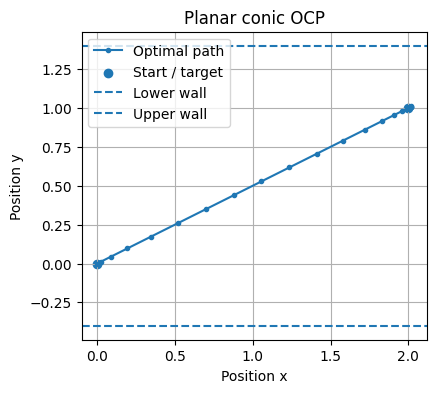

Largest acceleration norm: 1.1999999999990292
Largest speed: 0.9999999999993922


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x[:, 0], x[:, 1], marker=".", label="Optimal path")
ax.scatter([x0[0], target[0]], [x0[1], target[1]], label="Start / target")
ax.axhline(-0.4, linestyle="--", label="Lower wall")
ax.axhline(1.4, linestyle="--", label="Upper wall")
ax.set(xlabel="Position x", ylabel="Position y", title="Planar conic OCP")
ax.set_aspect("equal", adjustable="box")
ax.grid(True)
ax.legend()
plt.show()

acceleration_norm = np.linalg.norm(u, axis=1)
speed = np.linalg.norm(x[:, 2:], axis=1)
print("Largest acceleration norm:", acceleration_norm.max())
print("Largest speed:", speed.max())
assert acceleration_norm.max() <= acceleration_limit + TOLERANCE
assert speed.max() <= speed_limit + TOLERANCE

## Adapt this model
Keep the row order and SOC signs when adding constraints. `soc_sizes=(3, 3)` means
two three-dimensional cones at **each** stage, not six scalar inequalities.

The HPIPM QP adapter in the comparison notebook does not support these generic SOCs;
it reports them as unsupported rather than changing the problem.

Next: [a complete MPC loop](06_mpc_updates.ipynb).